# Simulated liquid water content at Powder Patch and Weissfluhjoch

Compare the Powder Patch mixed-forcing soil run (WY 2025) with the SNOWPACK
Weissfluhjoch study-plot example (MST96, WY 1996). Both panels use the Figure 7
color scale (0–4 vol. %) and a common snow-depth scale.

The two winters are aligned by month and day on an October–July axis. Each
panel shows the original calendar years. For illustration, dates before and
after output coverage are drawn as snow-free. The reference winter includes
February 29. The PPSA display repeats its February 28 profiles for that
extra day so the timeline stays continuous.
The files in the run_snowpack examples folder link to the existing model outputs.


In [1]:
from dataclasses import replace
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import pandas as pd
import seaborn as sns

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'figures/notebooks/snowpack_profiles.py').is_file())
sys.path.insert(0, str(root / 'figures/notebooks'))
from snowpack_profiles import Profile, _draw_layers, read_profiles, save_figure

examples = Path('/home/cassie/python/models/run_snowpack/examples/liquid_water_comparison')
cases = (
    ('Powder Patch (PPSA), Southeast Alaska', examples / 'ppsa_WY2025.pro', 2024),
    ('Weissfluhjoch (MST96), Swiss Alps', examples / 'weissfluhjoch_WY1996.pro', 1995),
)
sample_hours = 3
variable = 'liquid_water'

# The reference winter includes February 29 so month/day positions agree.
reference_start = pd.Timestamp('1999-10-01')
reference_stop = pd.Timestamp('2000-07-01')


def aligned_time(time):
    year = reference_start.year if time.month >= 10 else reference_stop.year
    return time.replace(year=year)



def display_profiles(profiles, cadence, year):
    aligned = [replace(profile, time=aligned_time(profile.time)) for profile in profiles]
    day = pd.Timedelta(days=1)
    if not pd.Timestamp(year + 1, 2, 1).is_leap_year:
        leap_day = pd.Timestamp('2000-02-29')
        repeated = [replace(profile, time=profile.time + day) for profile in aligned
                    if leap_day - day <= profile.time < leap_day]
        aligned = sorted([*aligned, *repeated], key=lambda profile: profile.time)

    step = pd.Timedelta(days=cadence)
    empty = aligned[0].top_cm[:0]
    before = pd.date_range(aligned[0].time - step, reference_start, freq=-step)[::-1]
    after = pd.date_range(aligned[-1].time + step, reference_stop, freq=step)
    return [*[Profile(time, empty, empty, {}) for time in before],
            *aligned, *[Profile(time, empty, empty, {}) for time in after]]


In [2]:
series = []
for _, profile_path, year in cases:
    start = pd.Timestamp(year, 10, 1)
    stop = pd.Timestamp(year + 1, 7, 1)
    profiles, cadence = read_profiles(profile_path, start, stop, (variable,),
                                      sample_hours=sample_hours)
    series.append((display_profiles(profiles, cadence, year), cadence, start, stop))


def draw_comparison(heading, panel_titles, *, subtitle=None):
    with sns.axes_style('darkgrid', {'axes.facecolor': '#f6f6fa'}), mpl.rc_context({
        'font.family': 'DejaVu Sans', 'pdf.fonttype': 42,
    }):
        fig = plt.figure(figsize=(12, 7.8))
        grid = fig.add_gridspec(2, 2, left=0.12, right=0.92, bottom=0.10, top=0.84,
                               width_ratios=(0.022, 1), wspace=0.08, hspace=0.34)
        fig.text(0.12, 0.97, heading,
                 va='top', fontsize=16, weight='bold')
        if subtitle:
            fig.text(0.12, 0.933, subtitle, va='top', fontsize=10, color='#45515a')
        for index, (title, (aligned, cadence, start, stop)) in enumerate(zip(panel_titles, series)):
            cax = fig.add_subplot(grid[index, 0])
            ax = fig.add_subplot(grid[index, 1])
            _draw_layers(ax, cax, aligned, variable, cadence, limits=None)

            native_ticks = pd.date_range(start, stop, freq='MS')
            tick_positions = mdates.date2num([aligned_time(date) for date in native_ticks])
            labels = [f'1 {date:%b}\n{date.year}' for date in native_ticks]
            ax.set_xticks(tick_positions, labels)
            ax.set_xlim(reference_start, reference_stop)
            ax.set_ylim(0, 250)
            ax.yaxis.tick_right()
            ax.yaxis.set_label_position('right')
            ax.set_ylabel('snow depth (cm)')
            ax.yaxis.set_major_locator(MultipleLocator(50))
            ax.tick_params(labelsize=9)
            ax.tick_params(axis='x', bottom=True, length=5, width=0.8, color='#46515b')
            ax.set_title(title, loc='left', fontsize=12)
            ax.text(0.009, 0.96, f'{chr(65 + index)})', transform=ax.transAxes,
                    va='top', fontsize=10, color='dimgrey', zorder=4,
                    bbox=dict(facecolor=ax.get_facecolor(), edgecolor='none', pad=1))
    return fig

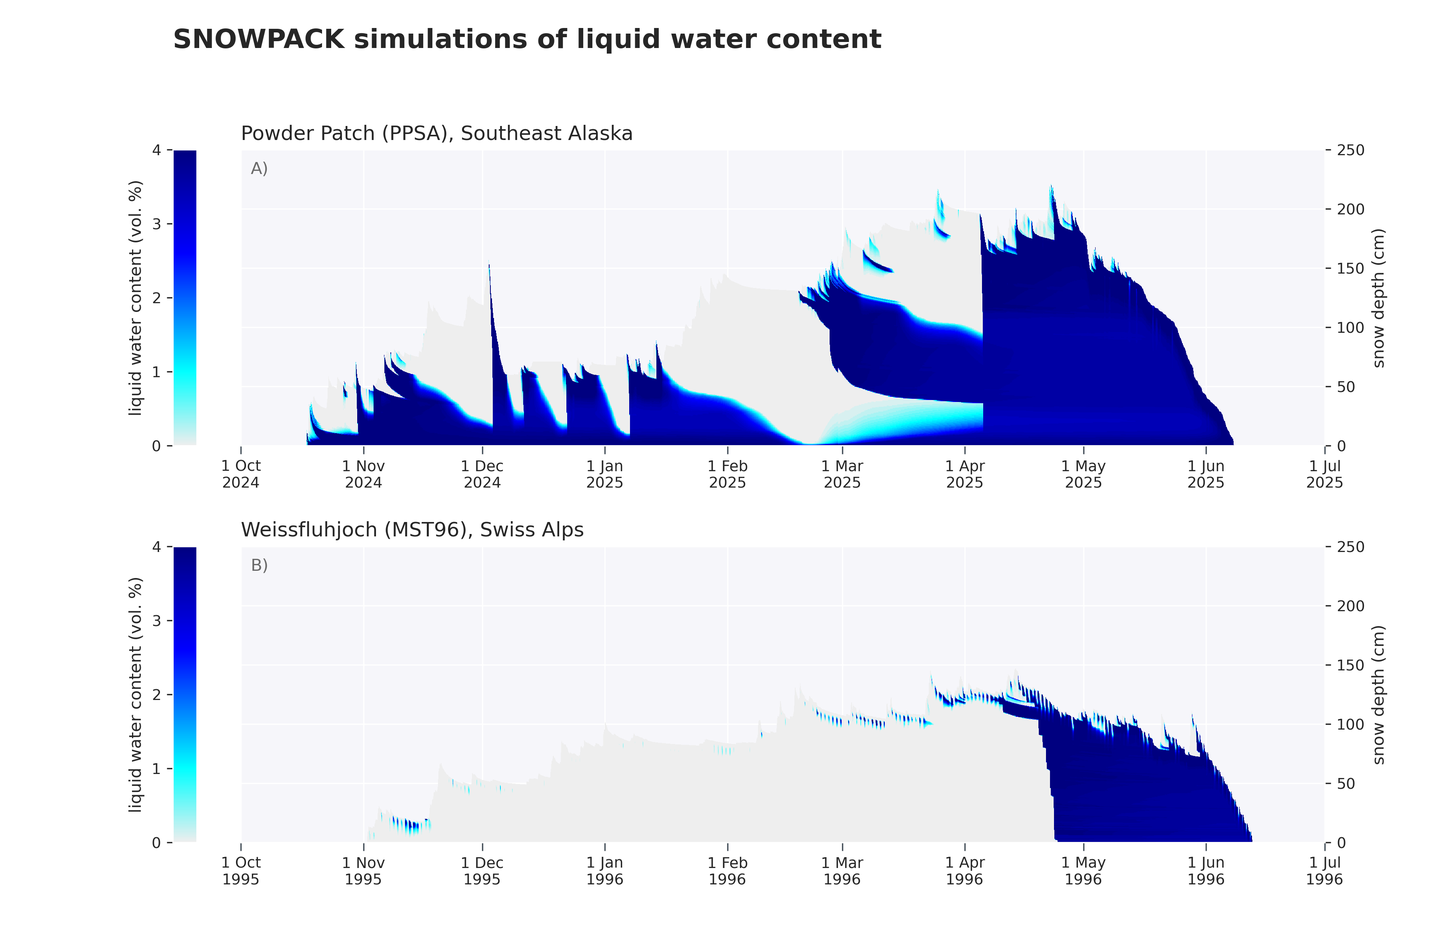

In [3]:
fig = draw_comparison('SNOWPACK simulations of liquid water content',
                      [title for title, _, _ in cases])
save_figure(fig, root / 'figures/files', 'figureX_compare_liquid_water_swiss')
plt.show()

## Presentation version

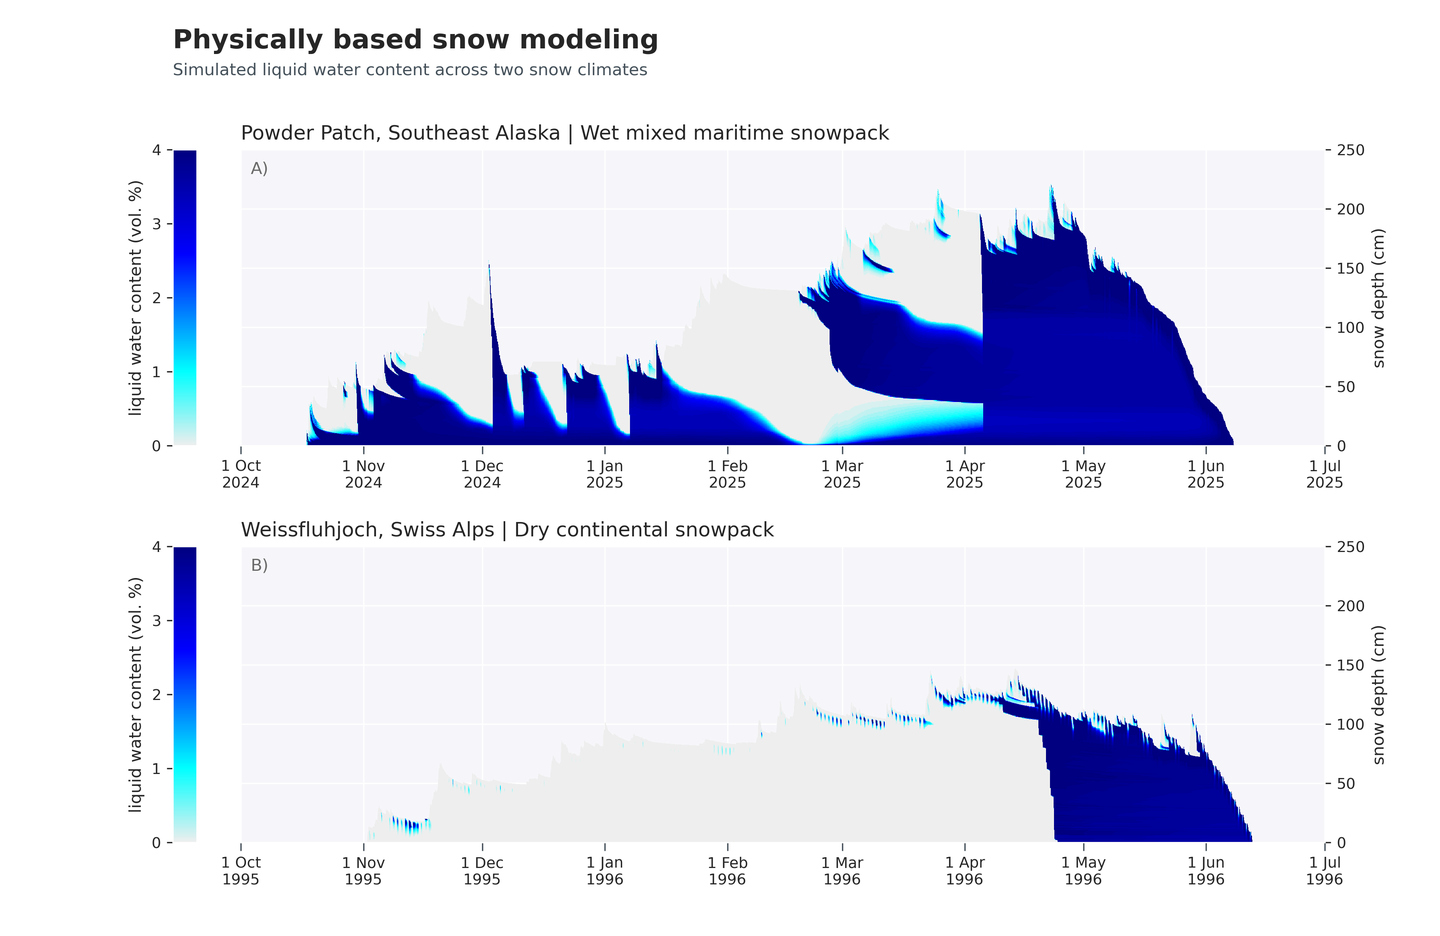

In [4]:
presentation = draw_comparison(
    'Physically based snow modeling',
    (
        'Powder Patch, Southeast Alaska | Wet mixed maritime snowpack',
        'Weissfluhjoch, Swiss Alps | Dry continental snowpack',
    ),
    subtitle='Simulated liquid water content across two snow climates',
)
save_figure(presentation, root / 'figures/files', 'figureX_compare_liquid_water_swiss_presentation')
plt.show()